# 03 · Known failures and OOD shifts

The lab's monitors separate **success / known failure / OOD** (Ho et al.), so the generator
produces all three, with labels that keep *what was injected* separate from *what physically
happened*:

| field (annotations.json) | meaning |
|---|---|
| `category` | how the episode was generated: `nominal`, `known_failure`, `ood` |
| `injected_failure` | type, severity ∈ [0,1] and the concrete drawn parameters |
| `outcome` | `success` iff the target port is latched and the gripper has let go |
| `failure_mode` | physical outcome: `dropped`, `jammed`, `not_seated`, `wrong_port`, `grasp_missed`, … |
| `injection_time_s`, `drop_times_s`, `latch_time_s` | event times for detection-delay metrics |

**Known failures** (the expert corrupts its own behaviour):
`drop` (the real dataset's main failure: gripper opens during transport), `weak_grip`,
`misalign` (biased port estimate, no search), `partial_insert`, `wrong_port`, `misgrasp`
(onto the plug body or the cable), `bump` (a knock on the gripper).

**OOD shifts** (outside the nominal randomisation ranges): `lighting`, `cable_color`,
`camera_shift`, `distractors`, `heavy_cable`, `slippery`, `panel_color`. The scripted expert
uses privileged state, so it mostly still succeeds under OOD. These shifts are meant to break the
*learned* models (policy, world model) that only see pixels and proprioception.

In [1]:
# Setup cell, inlined into every notebook by notebooks/build.py.
# Locally: finds the repo. On a Colab runtime (also VS Code connected to Colab), where the code is not
# on the VM: fetches it from (1) PLUGSIM_REPO (git URL, default: the public repo), (2) /content/RobotPluggingSim.zip, or
# (3) MyDrive/RobotPluggingSim (Drive), installs it, and keeps data/ + runs/ on Drive when mounted.
import os, sys, pathlib, subprocess
DEFAULT_REPO = "https://github.com/carlo-scr/RobotPluggingSim.git"
PLUGSIM_REPO = os.environ.get("PLUGSIM_REPO") or DEFAULT_REPO  # Colab: code is cloned from here
USE_DRIVE = os.environ.get("PLUGSIM_DRIVE", "1") == "1"  # set False if drive.mount hangs in your client
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
if IN_COLAB:
    # numpy's BLAS: one thread (the sim solves tiny systems; extra threads only add contention)
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("MUJOCO_GL", "egl")
    os.environ.setdefault("PYOPENGL_PLATFORM", "egl")
    CODE = pathlib.Path("/content/RobotPluggingSim")
    DRIVE = pathlib.Path("/content/drive/MyDrive")
    if (CODE / ".git").exists():
        subprocess.run(["git", "-C", str(CODE), "pull", "-q"])  # pick up pushed changes
    if not (CODE / "plugsim").exists():
        if PLUGSIM_REPO:
            subprocess.run(["git", "clone", "-q", PLUGSIM_REPO, str(CODE)], check=True)
        elif pathlib.Path("/content/RobotPluggingSim.zip").exists():
            subprocess.run(["unzip", "-q", "-o", "/content/RobotPluggingSim.zip", "-d", "/content"], check=True)
    if USE_DRIVE and not DRIVE.exists():
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:  # e.g. not supported by the client; fine with PLUGSIM_REPO or the zip
            print("Drive not mounted:", e)
    if not (CODE / "plugsim").exists():
        if (DRIVE / "RobotPluggingSim").exists():
            subprocess.run(["rsync", "-a", "--exclude", ".venv", "--exclude", "data", "--exclude", "runs", "--exclude", "media",
                            f"{DRIVE}/RobotPluggingSim/", f"{CODE}/"], check=True)
        else:  # last resort: the public repo
            subprocess.run(["git", "clone", "-q", DEFAULT_REPO, str(CODE)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(CODE)], check=True)
    if DRIVE.exists():  # persist datasets and checkpoints across sessions / notebooks
        for d in ("data", "runs"):
            tgt = DRIVE / "plugsim_runs" / d
            tgt.mkdir(parents=True, exist_ok=True)
            link = CODE / d
            if not link.is_symlink():
                subprocess.run(["rm", "-rf", str(link)])
                link.symlink_to(tgt)
    else:
        print("WARNING: no Drive: data/ and runs/ live on the VM and are lost when the runtime stops")
    try:
        import torch
        if torch.cuda.is_available():
            os.environ.setdefault("PLUGSIM_SCALE", "a100")
    except ImportError:
        pass
    os.chdir(CODE)
ROOT = pathlib.Path.cwd()
while not (ROOT / "plugsim").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
if sys.platform.startswith("linux") and not os.environ.get("DISPLAY"):
    os.environ.setdefault("MUJOCO_GL", "egl")  # headless GPU nodes
print("ROOT:", ROOT, "| colab:", IN_COLAB, "| scale:", os.environ.get("PLUGSIM_SCALE", "local"))

ROOT: . | colab: False | scale: local


In [2]:
import os, sys, pathlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from plugsim.env import PlugEnv
from plugsim.datagen import EpisodeSpec, run_episode
from plugsim.failures import FAILURE_TYPES
from plugsim.scenario import OOD_TYPES
from plugsim.tools import image_grid, video_html

SEEDS_PER_CELL = 4         # laptop; 50+ on a GPU node for smooth severity curves
SEVERITIES = (0.2, 0.5, 0.9)

## Outcome matrix: success rate per failure type and severity

172 episodes in 367s


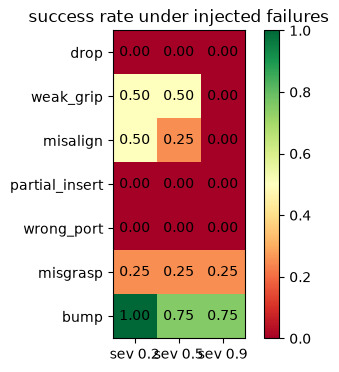

kind
ood:arm_gain_drift      1.00
ood:boot_color          1.00
ood:cable_color         1.00
ood:camera_noise        1.00
ood:camera_shift        1.00
ood:clutter             1.00
ood:dense_ports         1.00
ood:distractor_cable    1.00
ood:heavy_cable         1.00
ood:led_distractors     1.00
ood:lens_occlusion      1.00
ood:lighting_colored    1.00
ood:lighting_dim        1.00
ood:lighting_flicker    1.00
ood:lighting_harsh      1.00
ood:motion_blur         1.00
ood:overexposure        1.00
ood:panel_color         1.00
ood:rack_offset         1.00
ood:slippery            1.00
ood:stiff_cable         1.00
ood:weak_gripper        0.75


In [3]:
env = PlugEnv()
rows, t = [], time.time()
for kind in FAILURE_TYPES:
    for sev in SEVERITIES:
        for s in range(SEEDS_PER_CELL):
            a = run_episode(env, EpisodeSpec(seed=2000 + s, category="known_failure", failure=kind, severity=sev), cameras=[], save_states=False)["annotations"]
            rows.append(dict(kind=kind, severity=sev, success=a["outcome"] == "success", mode=a["failure_mode"]))
for o in OOD_TYPES:
    for s in range(SEEDS_PER_CELL):
        a = run_episode(env, EpisodeSpec(seed=2000 + s, category="ood", ood=[o]), cameras=[], save_states=False)["annotations"]
        rows.append(dict(kind=f"ood:{o}", severity=np.nan, success=a["outcome"] == "success", mode=a["failure_mode"]))
R = pd.DataFrame(rows)
print(f"{len(R)} episodes in {time.time() - t:.0f}s")
M = R[R.kind.isin(FAILURE_TYPES)].pivot_table(index="kind", columns="severity", values="success", aggfunc="mean").loc[list(FAILURE_TYPES)]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(M.values, cmap="RdYlGn", vmin=0, vmax=1)
ax.set_xticks(range(len(M.columns)), [f"sev {c}" for c in M.columns]); ax.set_yticks(range(len(M.index)), M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center")
ax.set_title("success rate under injected failures"); plt.colorbar(im); plt.show()
print(R[R.kind.str.startswith("ood")].groupby("kind").success.mean().to_string())

In [4]:
pd.crosstab(R.kind, R["mode"])

mode,dropped,grasp_missed,jammed,none,not_seated,wrong_port
kind,,,,,,
bump,0,0,0,10,2,0
drop,12,0,0,0,0,0
misalign,0,0,5,3,4,0
misgrasp,0,3,0,3,6,0
ood:arm_gain_drift,0,0,0,4,0,0
ood:boot_color,0,0,0,4,0,0
ood:cable_color,0,0,0,4,0,0
ood:camera_noise,0,0,0,4,0,0
ood:camera_shift,0,0,0,4,0,0


## What the failures look like
The active gripper's front camera at the moment the failure shows: the first frame after
injection, or the last frame for slow failures.

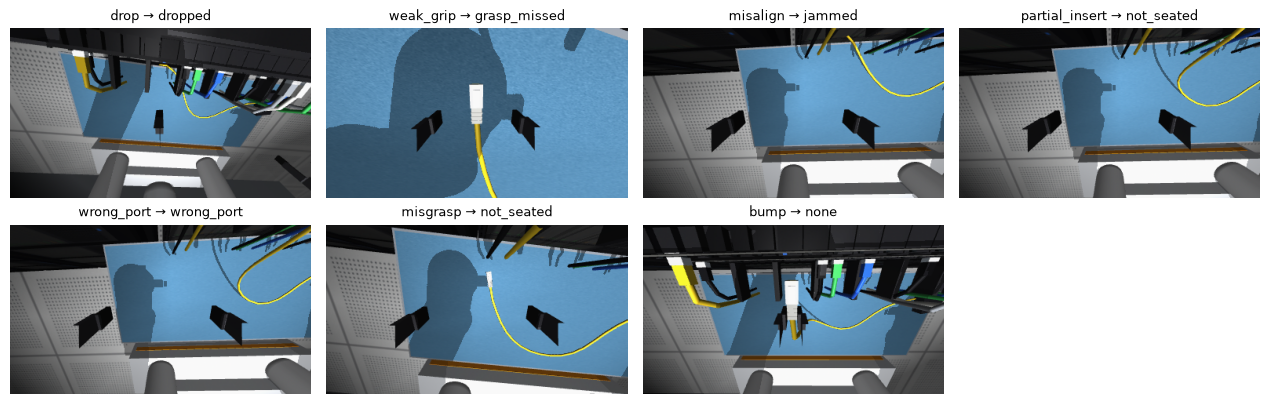

In [5]:
imgs, titles = [], []
for kind in FAILURE_TYPES:
    ep = run_episode(env, EpisodeSpec(seed=2001, category="known_failure", failure=kind, severity=0.9),
                     cameras=["right_gripper_front", "left_gripper_front"], save_states=False)
    A = ep["annotations"]; cam = f"{A['active_arm']}_gripper_front"
    t = np.asarray(ep["data"]["t"])
    te = (A["drop_times_s"] or [None])[0] or A["injection_time_s"]
    k = len(t) - 1 if te is None or kind in ("partial_insert", "misalign", "wrong_port") else min(len(t) - 1, int(np.searchsorted(t, te)) + 8)
    imgs.append(ep["frames"][cam][k]); titles.append(f"{kind} → {A['failure_mode']}")
image_grid(imgs, titles, cols=4); plt.show()

## The canonical failure: a drop during transport

In [6]:
ep = run_episode(env, EpisodeSpec(seed=2003, category="known_failure", failure="drop", severity=0.6),
                 cameras=["head_front", "right_gripper_front", "left_gripper_front"], save_states=False)
A = ep["annotations"]; cam = f"{A['active_arm']}_gripper_front"
print({k: A[k] for k in ("failure_mode", "injection_time_s", "drop_times_s", "duration_s")})
video_html([np.concatenate([a, b], 1) for a, b in zip(ep["frames"]["head_front"], ep["frames"][cam])], fps=20, width=760)

{'failure_mode': 'dropped', 'injection_time_s': 3.48, 'drop_times_s': [3.55], 'duration_s': 7.45}
